In [10]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\nehak

Files in this folder:
['.bash_history', '.copilot', '.git', '.git-for-windows-updater', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.python_history', '.streamlit', '.vscode', '.vscode-shared', '3D Objects', 'AppData', 'Application Data', 'battery-report.html', 'churnanalysisb.ipynb', 'churn_analysis.ipynb', 'Contacts', 'Cookies', 'customer_churn.db', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'netflix churn analysis.ipynb', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{f7f6c72b-4be3-11f1-a9a2-1867b0205ed3}.TM.blf', 'NTUSER.DAT{f7f6c72b-4be3-11f1-a9a2-1867b0205ed3}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{f7f6c72b-4be3-11f1-a9a2-1867b0205ed3}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Untitled1.ipynb',

In [9]:
import os

download_path = r"C:\Users\nehak\Downloads"

for file in os.listdir(download_path):
    if file.lower().endswith(".csv"):
        print(file)

netflix_customer_churn.csv


In [7]:
import pandas as pd

file_path = r"C:\Users\nehak\Downloads\netflix_customer_churn.csv"
df = pd.read_csv(file_path)

print("CSV loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

CSV loaded successfully
Dataset shape: (5000, 14)


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [17]:
print(df.columns.tolist())

['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'monthly_fee', 'churned', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre']


In [19]:
print("Totalrows:", df.shape[0])
print("Total columns:", df.shape[1])

Totalrows: 5000
Total columns: 14


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 920.1

In [3]:
#count missing values in each column
print(df.isnull().sum())

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


In [4]:
#checking for duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
#identify churn column
print(df["churned"].value_counts(dropna=False))

churned
1    2515
0    2485
Name: count, dtype: int64


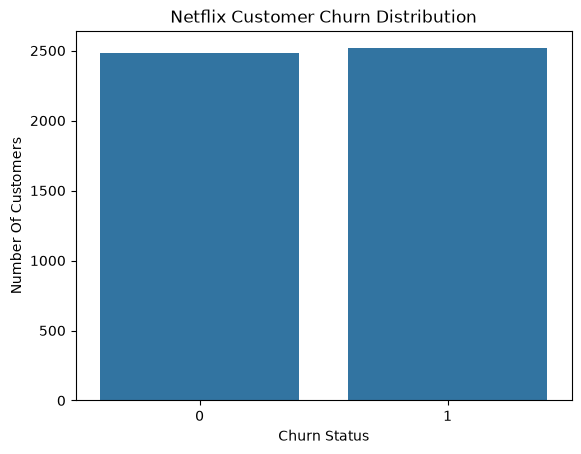

In [8]:
#MAKING CHART WHICH WILL SHOW CHURNED AND RETAINED CUSTOMERS
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x= "churned")

plt.title("Netflix Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number Of Customers")
plt.show()

In [8]:
#Data cleaning
df_clean = df.copy()

print("Original datasets:", df.shape)
print("Working datasets:", df_clean.shape)

Original datasets: (5000, 14)
Working datasets: (5000, 14)


In [10]:
#cleaning columns names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
print(df_clean.columns.tolist())

['customer_id', 'age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'monthly_fee', 'churned', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre']


In [12]:
#remove duplicate rows
print("Duplicates before:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

print("Duplicates after:", df_clean.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [15]:
#checking for missing values
missing_values = df_clean.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [4]:
# summarise dataset
display(df_clean.head())

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [3]:
#values of categorical columns
for col in df_clean.select_dtypes(include="object").columns:
    print("\nColumn:", col)

    


Column: customer_id

Column: gender

Column: subscription_type

Column: region

Column: device

Column: payment_method

Column: favorite_genre


C:\Users\nehak\AppData\Local\Temp\ipykernel_1740\253998568.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:


In [4]:
# search for churn column
[col for col in df_clean.columns if "churned" in col.lower()]

['churned']

In [5]:
print(df_clean["churned"].value_counts(dropna=False))

churned
1    2515
0    2485
Name: count, dtype: int64


In [7]:
# Calculate churn rate
total_customers = len(df_clean)
churned_customers = (df_clean["churned"] == 1).sum()
churn_rate = (churned_customers/total_customers)*100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2),"%")

Total Customers: 5000
Churned Customers: 2515
Churn Rate: 50.3 %


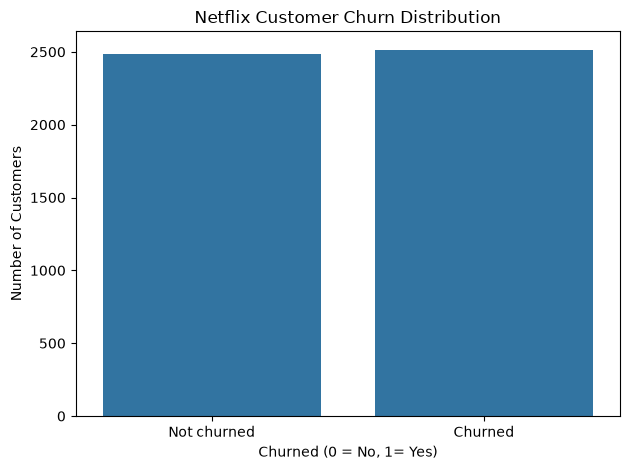

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_clean, x="churned")
plt.title("Netflix Customer Churn Distribution")
plt.xlabel("Churned (0 = No, 1= Yes)")
plt.ylabel("Number of Customers")
plt.xticks([0,1], ["Not churned", "Churned"])
plt.tight_layout()
plt.show()


In [14]:
#Analysing churn by subscription type
subscription_churn = df_clean.groupby("subscription_type")["churned"].mean()*100

print(subscription_churn.round(2))

subscription_type
Basic       61.83
Premium     43.71
Standard    45.44
Name: churned, dtype: float64


NameError: name 'plt' is not defined

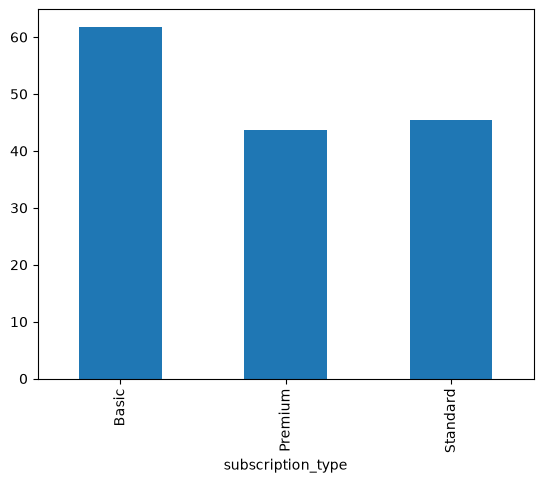

In [15]:
#Bar chart
subscription_churn.plot(kind="bar")

plt.title("Churn rate by subscription")
plt.xlabel("Subscription type")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
#Churn rate by region
region_churn = (df_clean.groupby("region")["churned"].mean().mul(100).sort_values(ascending=False))
print(region_churn.round(2))

region
Europe           51.67
South America    51.43
Asia             50.65
Oceania          50.07
North America    49.47
Africa           48.32
Name: churned, dtype: float64


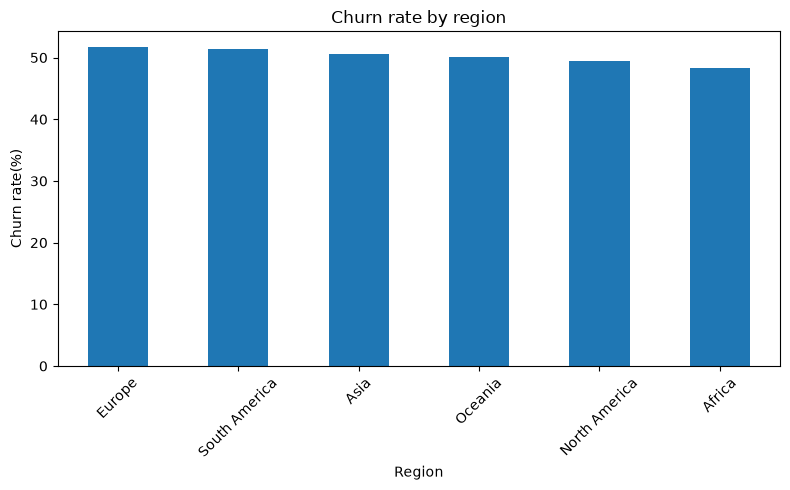

In [11]:
# now we will make chart of this
import matplotlib.pyplot as plt

region_churn.plot(kind="bar", figsize=(8,5))

plt.title("Churn rate by region")
plt.xlabel("Region")
plt.ylabel("Churn rate(%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:
#Churn rate by device
import matplotlib.pyplot as plt
device_churn = (df_clean.groupby("device")["churned"].mean().mul(100).sort_values(ascending=False))

print(device_churn.round(2))

device
Laptop     51.79
Mobile     50.50
Tablet     50.00
TV         49.95
Desktop    49.21
Name: churned, dtype: float64


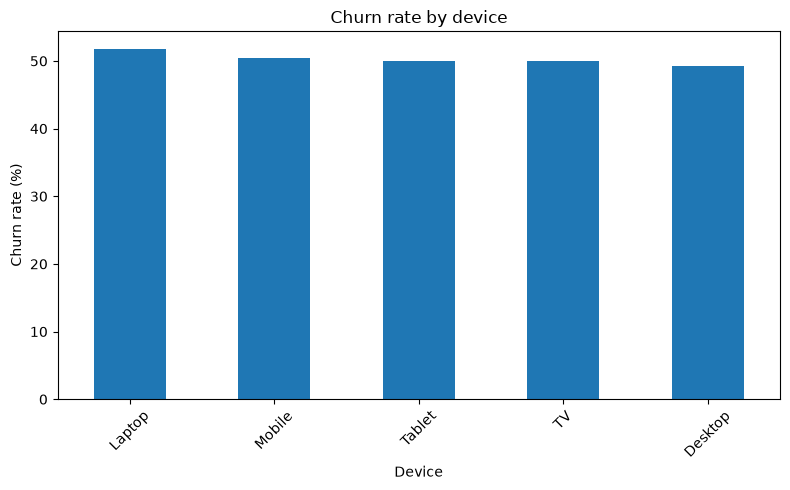

In [13]:
#now we will make chart of this
device_churn.plot(kind="bar", figsize=(8,5))

plt.title("Churn rate by device")
plt.xlabel("Device")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
#Churn rate by payment method
payment_churn= (df_clean.groupby("payment_method")["churned"].mean().mul(100).sort_values(ascending=False))
print(payment_churn.round(2))

payment_method
Crypto         59.70
Gift Card      57.79
PayPal         47.08
Debit Card     43.69
Credit Card    43.58
Name: churned, dtype: float64


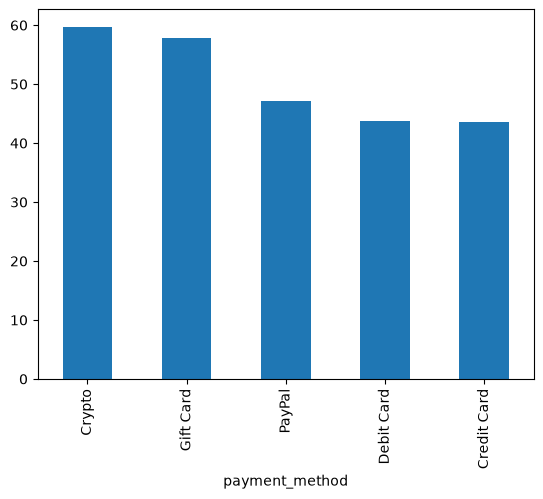

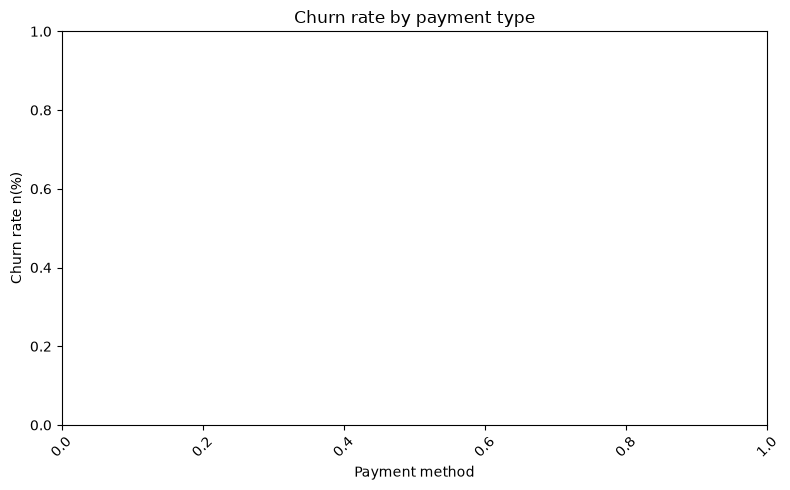

In [17]:
# now we will make chart of this
payment_churn.plot(kind="bar")
plt.figure(figsize=(8,5))

plt.title("Churn rate by payment type")
plt.xlabel("Payment method")
plt.ylabel("Churn rate n(%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
#Churn anlaysis based on favourite genre
genre_churn= (df_clean.groupby("favorite_genre")["churned"].mean().mul(100).sort_values(ascending=False))
print(genre_churn.round(2))

favorite_genre
Action         52.37
Drama          52.26
Horror         51.47
Documentary    50.75
Comedy         49.93
Romance        48.28
Sci-Fi         47.08
Name: churned, dtype: float64


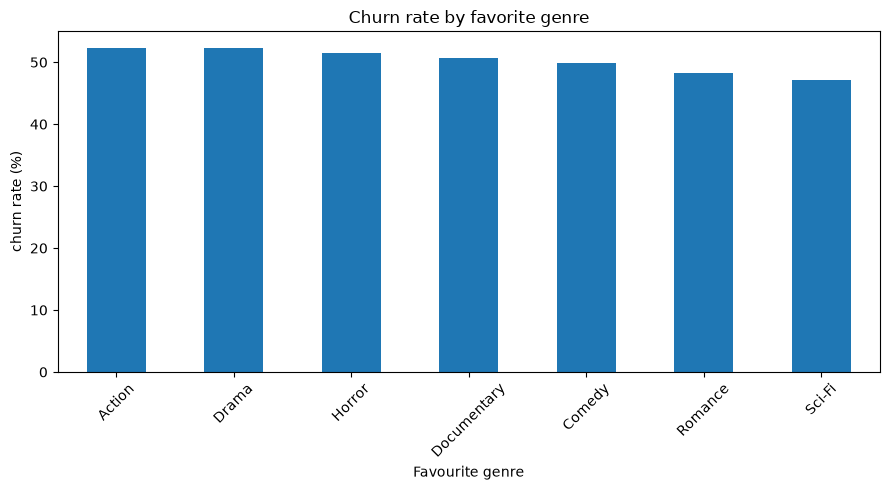

In [20]:
#Genre wise chart
plt.figure(figsize=(9,5))
genre_churn.plot(kind="bar")
plt.title("Churn rate by favorite genre")
plt.xlabel("Favourite genre")
plt.ylabel("churn rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

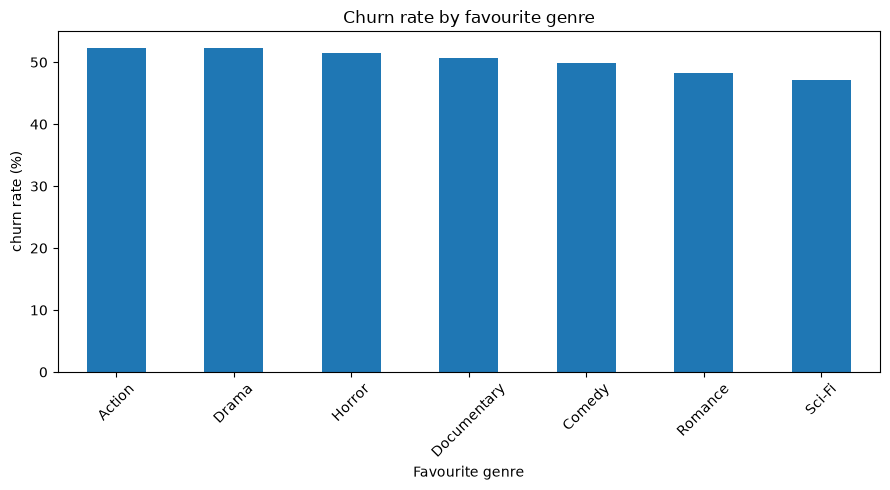

Chart saved successfully!


In [22]:
import os
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(9,5))
genre_churn.plot(kind="bar")
plt.title("Churn rate by favourite genre")
plt.xlabel("Favourite genre")
plt.ylabel("churn rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/genre_churn.png",dpi=300, bbox_inches="tight")
plt.show()
print("Chart saved successfully!")

In [24]:
#Comparing all churn rates
print("Overall churn rates:",round(df_clean["churned"].mean()*100,2), "%")
print("\nSubscription-wise churn:")
print(subscription_churn.round(2))

print("\nRegion-wise churn:")
print(region_churn.round(2))

print("\nDevice-wise churn:")
print(device_churn.round(2))

print("\nPayment-wise churn:")
print(payment_churn.round(2))

print("\nGenre-wise churn:")
print(genre_churn.round(2))

Overall churn rates: 50.3 %

Subscription-wise churn:
subscription_type
Basic       61.83
Premium     43.71
Standard    45.44
Name: churned, dtype: float64

Region-wise churn:
region
Europe           51.67
South America    51.43
Asia             50.65
Oceania          50.07
North America    49.47
Africa           48.32
Name: churned, dtype: float64

Device-wise churn:
device
Laptop     51.79
Mobile     50.50
Tablet     50.00
TV         49.95
Desktop    49.21
Name: churned, dtype: float64

Payment-wise churn:
payment_method
Crypto         59.70
Gift Card      57.79
PayPal         47.08
Debit Card     43.69
Credit Card    43.58
Name: churned, dtype: float64

Genre-wise churn:
favorite_genre
Action         52.37
Drama          52.26
Horror         51.47
Documentary    50.75
Comedy         49.93
Romance        48.28
Sci-Fi         47.08
Name: churned, dtype: float64


#Business Insights and recommendations
##1. Key insights

_ **Subscription type:** Basic plan has the highest observed churn rate.
 _**Region churn:** Europe and South America show relativeely high churn rate.
_**Device:** Laptop users have the highest observed churn rates.
_**Payment method:** Crypto and Gift card users show higher churn rates.
_**Favourite genre:** Action viewers have the highest observed churn rates while Sci-Fi viewers have the lowest.

## Business recommendations
- Investigate why basic plan customers leave.
- Study customer preferences across regions.
- Improve the viewing experience on laptops. 
- Investigate payment related issues.
- Study content engagement across genes.

## Conclusion
This project analyses customer churn patterns using python,pandas, matplotlib,and seaborn . The finding identify customer segments that may need further investigation and targeted retention strategies.
    

In [21]:
#Final summary table
summary = pd.DataFrame({"Analysis": ["Subscription", "Region", "Device", "Payment Method", "Favorite Genre"],
                        "Highest Churn Category": [subscription_churn.idxmax(), region_churn.idxmax(), device_churn.idxmax(), payment_churn.idxmax(), genre_churn.idxmax()], "Churn Rate (%)": [ subscription_churn.max(), region_churn.max(), device_churn.max(), payment_churn.max(), genre_churn.max()]})

display(summary.round(2))

,Analysis,Highest Churn Category,Churn Rate (%)
0,Subscription,Basic,61.83
1,Region,Europe,51.67
2,Device,Laptop,51.79
3,Payment Method,Crypto,59.70
4,Favorite Genre,Action,52.37


In [23]:
# Export final summary to CSV
summary.to_csv("netflix_churn_summary.csv")
print("CSV file exported successfully!")
print("File name: netflix_churn_summary.csv")


CSV file exported successfully!
File name: netflix_churn_summary.csv


In [24]:
import os
import matplotlib.pyplot as plt
os.makedirs("Netflix_Churn_Charts")
for i, num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(num)
    fig.savefig(
        f"Netflix_Churn_Charts/chart_{i}.png", dpi=300, bbox_inches="tight")

print("All Charts saved successfully!")


All Charts saved successfully!


FINAL CONCLUSION
1. PROJECT OVERVIEW
 The objective of this project was to analyse customer churn patterns and identify the factors associated with customer cancellations. the analysis was performed using python , pandas , matplotlib , qa nd seaborn in jupyter notebook .
2. KEY FINDINGS
* The overall customer churn rate was approximately 50.3%.
* Basic subscription customera showed the highest churn rate.
* Europe and south america showed relatively highest churn rate.
* laptop users had the highest churn rate among the device categories.
* Crypto and gift card payment methods showed relative high churn rates.
* Customer churn varied across favorite genre.

3. BUSNESS RECOMMENDATIONS
* Review the pricing and benefits of the basic subscription.
* Investigate customer experience in regions with highest churn.
* Improve the viewing experiences in laptops.
* Analyse payment related problems and provide convenient payment options.
* Introduces personalised content recommendations and engagement campagins.
4. CONCLUSION
This project helped identify important customer churn patterns and demonstrated how data analysis can support business decision making.
Python and data visualisation techniques were used to convert raw customer data into meaningful insights.